<a href="https://colab.research.google.com/github/ShlokBagwe/Agri-AI-Bootcamp/blob/main/Agri_Day_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("patelris/crop-yield-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'crop-yield-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/crop-yield-prediction-dataset


In [14]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


files = [f for f in os.listdir(path) if f.endswith('.csv')]
csv_path = os.path.join(path, files[0])
df = pd.read_csv(csv_path)

In [15]:
df.head()

,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400


In [16]:
flag = df['Year'].is_monotonic_increasing
print(flag)

False


In [17]:
df.sort_values('Year', inplace=True)

In [18]:
X = df[['Area', 'Item', 'Year']]
y = df['Value']

In [19]:
import numpy as np
idx=np.random.default_rng(0).permutation(len(X))
cut=int(0.8*len(X)); tr,te=idx[:cut],idx[cut:]
print(y[tr].mean(), y[tr].var(), y[tr].std())

62275.39812223128 4619560608.8954115 67967.3495797461


In [22]:
x_raw = X['Year'].values
x_mean = x_raw[tr].mean()
x_std = x_raw[tr].std()


x = (x_raw[tr] - x_mean) / x_std
y_train = y.values[tr]

w = b = 0.0
lr = 0.01
losses = []

for e in range(500):
    err = w * x + b - y_train
    w -= lr * 2 * (err * x).mean()
    b -= lr * 2 * err.mean()
    loss = (err ** 2).mean()
    losses.append(loss)

print(f"Final w: {w:.4f}, b: {b:.4f}, loss: {loss:.5f}")

Final w: 9239.1327, b: 62210.4737, loss: 4533060040.97042


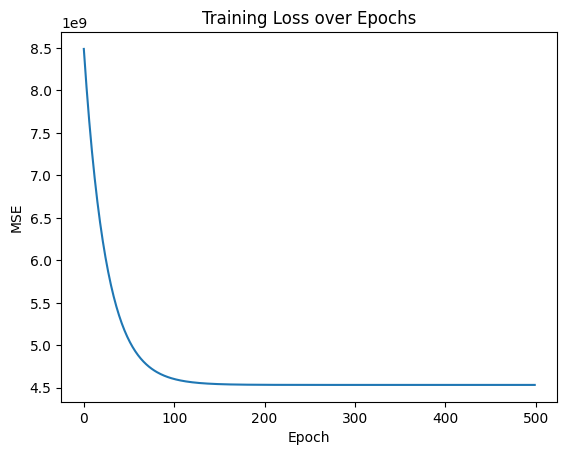

In [21]:
plt.plot(losses)
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.show()

In [28]:
rmse = np.sqrt(losses)
print(rmse[-5:])

[67328.00340264 67328.00340025 67328.00339795 67328.00339574
 67328.00339361]


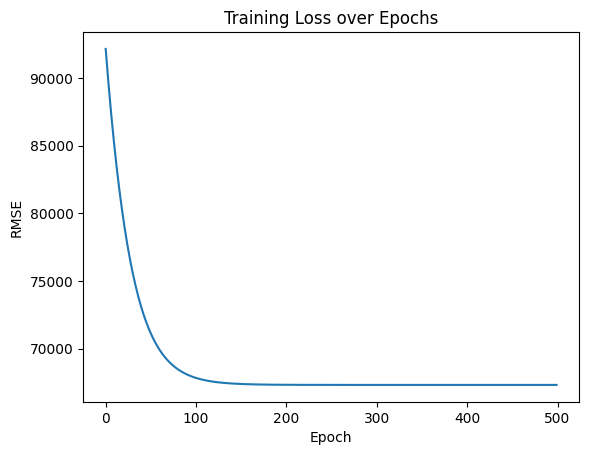

In [27]:
plt.plot(rmse)
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.show()